# Детектор SMS-спама и его устойчивость к обфускации

**Вопрос:** насколько легко обойти классический спам-фильтр, если спамер слегка искажает текст
(`free` → `fr3e`, `f.r.e.e`)? Какие модели устойчивее и какие защиты работают?

**План:** классические модели (TF-IDF + NB / LogReg, по словам и по символам) и небольшая char-CNN на PyTorch →
атаки обфускацией (случайная и white-box по самым «спамным» словам) → две защиты:
нормализация текста и обучение на искажённых примерах (adversarial augmentation).

Данные: [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (UCI, 5574 сообщения, CC BY 4.0).

In [1]:
import io, re, time, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

SEED = 42
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 1. Данные

In [2]:
DATA = Path("data/SMSSpamCollection")
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        DATA.write_bytes(z.read("SMSSpamCollection"))

df = pd.read_csv(DATA, sep="\t", header=None, names=["label", "text"], quoting=3, encoding="utf-8")
df["y"] = (df["label"] == "spam").astype(int)
df = df.drop_duplicates("text").reset_index(drop=True)          # дубликаты могли бы попасть и в train, и в test
print(df.shape, "| доля спама:", round(df["y"].mean(), 3))
df.groupby("label")["text"].agg(count="count", mean_len=lambda s: s.str.len().mean()).round(1)

(5171, 3) | доля спама: 0.126


,count,mean_len
label,,
ham,4518,70.9
spam,653,137.7


In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(df["text"], df["y"], test_size=0.25, stratify=df["y"], random_state=SEED)
X_tr, X_te, y_tr, y_te = X_tr.tolist(), X_te.tolist(), y_tr.to_numpy(), y_te.to_numpy()
print("train", len(X_tr), "test", len(X_te), "| спама в test:", y_te.sum())

train 3878 test 1293 | спама в test: 163


## 2. Модели

- **NB-words / LogReg-words** — TF-IDF по словам и биграммам;
- **LogReg-chars** — TF-IDF по символьным n-граммам (2–5) внутри слов;
- **CharCNN** — свёрточная сеть по символам (PyTorch), байты UTF-8 → эмбеддинги → свёртки 3/5/7 → max-pool.

In [4]:
def word_vec(): return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
def char_vec(): return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

def sk_models():
    return {
        "NB-words":     make_pipeline(word_vec(), MultinomialNB(alpha=0.1)),
        "LogReg-words": make_pipeline(word_vec(), LogisticRegression(C=20, max_iter=3000, class_weight="balanced")),
        "LogReg-chars": make_pipeline(char_vec(), LogisticRegression(C=20, max_iter=3000, class_weight="balanced")),
    }

MAXLEN = 200
def encode(texts):
    out = np.zeros((len(texts), MAXLEN), dtype=np.int64)
    for i, t in enumerate(texts):
        b = list(t.lower().encode("utf-8", "ignore"))[:MAXLEN]
        out[i, :len(b)] = np.array(b) + 1                       # 0 — паддинг
    return torch.from_numpy(out)

class CharCNN(nn.Module):
    def __init__(self, emb=32, ch=64):
        super().__init__()
        self.emb = nn.Embedding(257, emb, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb, ch, k, padding=k // 2) for k in (3, 5, 7)])
        self.drop = nn.Dropout(0.3); self.fc = nn.Linear(3 * ch, 1)
    def forward(self, x):
        h = self.emb(x).transpose(1, 2)
        h = torch.cat([torch.relu(c(h)).amax(dim=2) for c in self.convs], dim=1)
        return self.fc(self.drop(h)).squeeze(1)

class TorchClassifier:
    """Обёртка с интерфейсом fit / predict_proba, как у scikit-learn."""
    def __init__(self, epochs=12, lr=2e-3, bs=64): self.epochs, self.lr, self.bs = epochs, lr, bs
    def fit(self, texts, y):
        torch.manual_seed(SEED)
        self.net = CharCNN(); opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        X, Y = encode(texts), torch.tensor(y, dtype=torch.float32)
        pos_w = ((1 - Y.mean()) / Y.mean()).detach()          # балансировка классов
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
        g = torch.Generator().manual_seed(SEED)
        for _ in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(X), generator=g).split(self.bs):
                opt.zero_grad(); loss_fn(self.net(X[idx]), Y[idx]).backward(); opt.step()
        return self
    def predict_proba(self, texts):
        self.net.eval()
        with torch.no_grad(): p = torch.sigmoid(self.net(encode(texts))).numpy()
        return np.c_[1 - p, p]

def all_models(): return {**sk_models(), "CharCNN": TorchClassifier()}

def evaluate(m, X, y):
    p = m.predict_proba(X)[:, 1]; pred = (p >= 0.5).astype(int)
    return {"precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "PR-AUC": average_precision_score(y, p)}

models, rows = all_models(), []
for name, m in models.items():
    t = time.time(); m.fit(X_tr, y_tr)
    rows.append({"модель": name, **evaluate(m, X_te, y_te), "обучение, с": time.time() - t})
clean = pd.DataFrame(rows).set_index("модель")
clean.round(3)

,precision,recall,F1,PR-AUC,"обучение, с"
модель,,,,,
NB-words,0.980,0.902,0.939,0.977,0.137
LogReg-words,0.950,0.926,0.938,0.976,0.158
LogReg-chars,0.981,0.957,0.969,0.990,0.854
CharCNN,0.993,0.902,0.945,0.976,18.703


## 3. Атаки обфускацией

Спамер меняет только **спам-сообщения** (ham не трогаем), смысл для человека сохраняется:

- **leet** — замена букв похожими символами: `e→3, o→0, i→1, a→@, s→$, l→1`;
- **split** — разбивка слова точками или пробелами: `free → f.r.e.e`;
- **mix** — для каждого слова случайно leet или split;
- **homoglyph** — латинские буквы заменяются похожими кириллическими (`a→а`, `o→о`): на экране текст не меняется.
  Эту атаку используем только при проверке защит как «невиданную».

**Случайная атака:** каждое слово длиной ≥ 3 искажается с вероятностью `rate`.
**White-box атака:** спамер знает модель LogReg-words и искажает только её топ-k самых «спамных» слов.

In [5]:
LEET = str.maketrans({"e": "3", "o": "0", "i": "1", "a": "@", "s": "$", "l": "1"})
HOMO = str.maketrans("aeopcxyAEOPCXY", "аеорсхуАЕОРСХУ")   # латиница -> похожая кириллица

def obfuscate_word(w, mode, r):
    if mode == "homoglyph": return w.translate(HOMO)
    if mode == "mix": mode = "leet" if r.random() < 0.5 else "split"
    if mode == "leet":
        out = w.lower().translate(LEET)
        return out if out != w.lower() else ".".join(w)        # нечего заменять -> split
    return (r.choice([".", " ", "-"])).join(w)

def attack(texts, rate=0.3, mode="mix", targets=None, seed=0):
    r = np.random.default_rng(seed)
    def repl(m):
        w = m.group(0)
        hit = (w.lower() in targets) if targets is not None else (r.random() < rate)
        return obfuscate_word(w, mode, r) if hit else w
    return [re.sub(r"[A-Za-z]{3,}", repl, t) for t in texts]

spam_te = [t for t, y in zip(X_te, y_te) if y == 1]
example = next(t for t in spam_te if "free" in t.lower())
for mode in ["leet", "split", "mix", "homoglyph"]:
    print(f"{mode:5s}:", attack([example], rate=0.5, mode=mode, seed=1)[0][:110])
print("orig :", example[:110])

leet : Do you want a n3w Nokia 3510i c010ur ph0n3 DeliveredTomorrow? w1th 300 free m1nut3$ to any mobile + 100 fr33 t
split: Do you want a N-e-w N-o-k-i-a 3510i c.o.l.o.u.r p-h-o-n-e DeliveredTomorrow? W-i-t-h 300 free m-i-n-u-t-e-s to
mix  : Do you want a N.e.w N.o.k.i.a 3510i c.o.l.o.u.r phone DeliveredTomorrow? W.i.t.h 300 fr33 m1nut3$ to @ny mobil
homoglyph: Do you want a Nеw Nokia 3510i соlоur рhоnе DeliveredTomorrow? With 300 free minutеs to any mobile + 100 frее t
orig : Do you want a New Nokia 3510i colour phone DeliveredTomorrow? With 300 free minutes to any mobile + 100 free t


топ-15 «спамных» слов LogReg-words: ['txt', 'call', 'text', 'free', 'reply', 'www', 'uk', 'claim', 'mobile', 'stop', 'to', 'com', '150p', '50', 'chat']


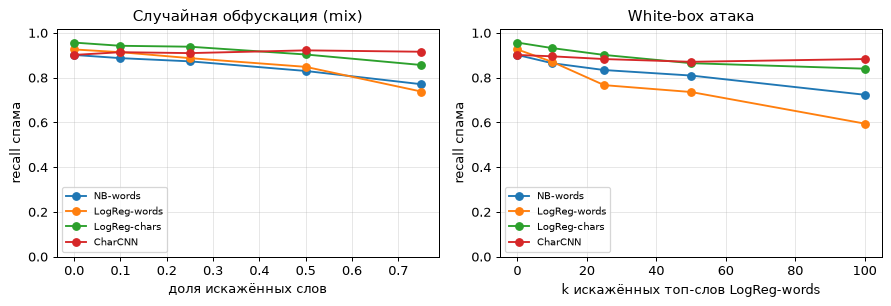

,recall спама
"NB-words, случ. rate=0.5",0.830
"LogReg-words, случ. rate=0.5",0.849
"LogReg-chars, случ. rate=0.5",0.904
"CharCNN, случ. rate=0.5",0.922
"NB-words, white-box k=50",0.810
"LogReg-words, white-box k=50",0.736
"LogReg-chars, white-box k=50",0.865
"CharCNN, white-box k=50",0.871


In [6]:
def spam_recall(m, texts):                   # доля искажённого спама, которую модель всё ещё ловит
    return float((m.predict_proba(texts)[:, 1] >= 0.5).mean())

rates = [0.0, 0.1, 0.25, 0.5, 0.75]
rand_res = {name: [np.mean([spam_recall(m, attack(spam_te, rate, "mix", seed=s)) for s in range(3)]) for rate in rates]
            for name, m in models.items()}

lr_words = models["LogReg-words"]
vocab = lr_words[0].get_feature_names_out(); coef = lr_words[-1].coef_[0]
top_spam = [vocab[i] for i in np.argsort(-coef) if " " not in vocab[i]]
ks = [0, 10, 25, 50, 100]
wb_res = {name: [spam_recall(m, attack(spam_te, mode="mix", targets=set(top_spam[:k]), seed=0)) for k in ks]
          for name, m in models.items()}
print("топ-15 «спамных» слов LogReg-words:", top_spam[:15])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name in models:
    ax[0].plot(rates, rand_res[name], "o-", label=name); ax[1].plot(ks, wb_res[name], "o-", label=name)
ax[0].set_xlabel("доля искажённых слов"); ax[0].set_title("Случайная обфускация (mix)")
ax[1].set_xlabel("k искажённых топ-слов LogReg-words"); ax[1].set_title("White-box атака")
for a in ax: a.set_ylabel("recall спама"); a.set_ylim(0, 1.02); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/attacks.png", bbox_inches="tight"); plt.show()

pd.DataFrame({**{f"{n}, случ. rate=0.5": [rand_res[n][3]] for n in models},
              **{f"{n}, white-box k=50": [wb_res[n][3]] for n in models}}, index=["recall спама"]).T.round(3)

## 4. Защиты

1. **Нормализация** перед моделью: склеиваем слова, разбитые точками или дефисами (пробелы не трогаем:
   `u r a` в SMS — обычные слова), и возвращаем
   leet-символы в буквы внутри слов, где есть хотя бы одна буква (номера телефонов и цены не трогаем).
2. **Adversarial augmentation:** добавляем к обучающей выборке искажённые копии спама (rate = 0.3, mix).

Оцениваем на чистом тесте (не испортили ли качество) и на трёх атаках: случайная mix (rate = 0.5),
white-box (k = 50) и **гомоглифы** (rate = 0.5) — тип искажения, которого не было ни в аугментации, ни в нормализации.

In [7]:
UNLEET = str.maketrans({"3": "e", "0": "o", "1": "i", "@": "a", "$": "s"})
SPLIT_RE = re.compile(r"\b(?:\w[.\-]){2,}\w\b")

def normalize(t):
    t = SPLIT_RE.sub(lambda m: re.sub(r"[.\-]", "", m.group(0)), t)
    return re.sub(r"[\w@$]+", lambda m: m.group(0).translate(UNLEET) if re.search(r"[A-Za-z]", m.group(0)) else m.group(0), t)

print(normalize("W1N a f.r.e.e pr1z3 n0w! Call 08712345678 for £1000"))

class Normalized:
    def __init__(self, m): self.m = m
    def fit(self, X, y): self.m.fit([normalize(t) for t in X], y); return self
    def predict_proba(self, X): return self.m.predict_proba([normalize(t) for t in X])

spam_tr = [t for t, y in zip(X_tr, y_tr) if y == 1]
X_aug = X_tr + attack(spam_tr, rate=0.3, mode="mix", seed=100)
y_aug = np.r_[y_tr, np.ones(len(spam_tr), dtype=int)]

atk_rand = attack(spam_te, 0.5, "mix", seed=0)
atk_wb = attack(spam_te, mode="mix", targets=set(top_spam[:50]), seed=0)
atk_homo = attack(spam_te, 0.5, "homoglyph", seed=0)
rows = []
for name in ["LogReg-words", "LogReg-chars", "CharCNN"]:
    variants = {"без защиты": models[name],
                "нормализация": Normalized(all_models()[name]).fit(X_tr, y_tr),
                "augmentation": all_models()[name].fit(X_aug, y_aug)}
    variants["норм. + aug."] = Normalized(all_models()[name]).fit(X_aug, y_aug)
    for dname, m in variants.items():
        rows.append({"модель": name, "защита": dname, "F1 (чистый тест)": evaluate(m, X_te, y_te)["F1"],
                     "recall: случ. 0.5": spam_recall(m, atk_rand), "recall: white-box k=50": spam_recall(m, atk_wb),
                     "recall: гомоглифы 0.5": spam_recall(m, atk_homo)})
defense = pd.DataFrame(rows).set_index(["модель", "защита"])
defense.round(3)

WiN a free prize now! Call 08712345678 for £1000


F1 (чистый тест)  recall: случ. 0.5  \
модель       защита                                              
LogReg-words без защиты               0.938              0.840   
             нормализация             0.935              0.896   
             augmentation             0.928              0.926   
             норм. + aug.             0.935              0.908   
LogReg-chars без защиты               0.969              0.902   
             нормализация             0.969              0.939   
             augmentation             0.959              0.988   
             норм. + aug.             0.962              0.963   
CharCNN      без защиты               0.945              0.902   
             нормализация             0.939              0.890   
             augmentation             0.956              0.994   
             норм. + aug.             0.950              0.920   

                           recall: white-box k=50  recall: гомоглифы 0.5  
модель       защита                                                       
LogReg-words без защиты                     0.736                  0.847  
             нормализация                   0.890                  0.847  
             augmentation                   0.822                  0.877  
             норм. + aug.                   0.890                  0.847  
LogReg-chars без защиты                     0.865                  0.920  
             нормализация                   0.926                  0.902  
             augmentation                   0.926                  0.933  
             норм. + aug.                   0.951                  0.920  
CharCNN      без защиты                     0.871                  0.963  
             нормализация                   0.883                  0.951  
             augmentation                   0.939                  0.982  
             норм. + aug.                   0.920                  0.957

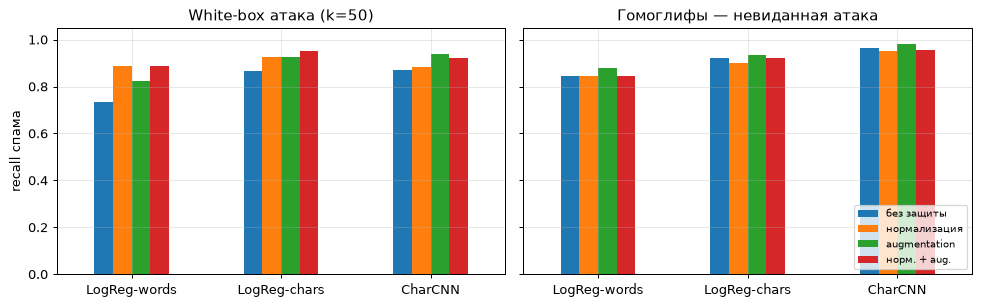

In [8]:
order_m = ["LogReg-words", "LogReg-chars", "CharCNN"]
order_d = ["без защиты", "нормализация", "augmentation", "норм. + aug."]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, col, title in [(ax[0], "recall: white-box k=50", "White-box атака (k=50)"),
                      (ax[1], "recall: гомоглифы 0.5", "Гомоглифы — невиданная атака")]:
    defense[col].unstack().loc[order_m, order_d].plot(kind="bar", ax=a, rot=0, legend=False)
    a.set_title(title); a.set_xlabel(""); a.set_ylim(0, 1.05)
ax[0].set_ylabel("recall спама"); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("images/defenses.png", bbox_inches="tight"); plt.show()

## 5. Выводы

- **На чистых данных** лучшая модель — TF-IDF по символьным n-граммам + логистическая регрессия:
  F1 = 0.969, PR-AUC = 0.990, обучение меньше секунды. CharCNN даёт самую высокую precision (0.993),
  но обучается в ~20 раз дольше и по F1 не выигрывает.
- **Обфускация ломает словесные модели.** White-box атака на 50 самых «спамных» слов снижает recall
  LogReg-words с 0.926 до 0.736: каждое четвёртое спам-сообщение проходит фильтр. Модели по символам
  теряют меньше (0.865–0.871), потому что n-граммы частично переживают замену отдельных букв.
- **Нормализация** — дешёвая и безопасная защита: для LogReg-words recall под white-box атакой
  растёт с 0.736 до 0.890 без потери F1 на чистом тесте (0.938 → 0.935).
- **Adversarial augmentation** сильнее всего помогает моделям по символам: LogReg-chars ловит 98.8%
  спама при случайной обфускации, а вместе с нормализацией — 95.1% при white-box атаке (F1 на чистом тесте 0.962).
- **Защиты не обобщаются на новые типы атак.** На гомоглифах (подмена латиницы кириллицей) нормализация
  не помогает, а аугментация даёт лишь +0.01–0.03 recall. Против такой атаки нужна отдельная мера
  (например, Unicode-нормализация «похожих» символов), то есть устойчивость надо проверять на атаках,
  которых модель не видела.
- **Ограничения:** небольшой англоязычный датасет 2012 года; атаки синтетические и не учитывают,
  насколько текст остаётся читаемым; white-box атака построена против одной модели; результат
  случайной атаки в таблице защит — по одной реализации (seed = 0), на графике выше — среднее по трём.